In [71]:
import sys
import numpy as np
import pandas as pd 
import sklearn
import matplotlib.pyplot as plt

In [72]:
from sklearn.model_selection import train_test_split

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [73]:
print(sys.version.split()[0], np.__version__, pd.__version__, sklearn.__version__)


3.12.6 2.0.2 2.3.3 1.6.1


Part 0  
0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0

In [74]:
SEED = 2463

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]

X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)

print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape, sep='\n')

(297, 14)
0.461
(207, 13)
(90, 13)


Part 1                      

1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1-1


In [75]:
toy = pd.DataFrame({
    "age_55_plus": [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male": [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp": [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease": [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})

1)<br>
total N = 12 <br>
patients with disease 1 N = 6; prop = 0.5 <br>
patients with disease 0 N = 6; prop. = 0.5 <br>
 

entropy formula: H(parent) = -(p1 * log2 (p1) + p0 * log2(p0)) = -(0.5 * log2(0.5) + 0.5 * log2(0.5)) = 1

entropy = 1

2)<br>
age_55_plus:<br>
    H1​ = −(5/6* ​log2​ 5/6 ​+ 1/6 ​log2​ 1/6​) = 0.650 <br>
    H2 = 0.650<br>
        IG = 1 - (6/12*0.650 +6/12*0.650) = 0.350<br><br>
exercise_angina:<br>
    H1 = 0 (theres no disease)<br>
    H2 = 0.811<br>
        IG = 0.459<br><br>
male:<br>
    H1 = 1<br>
    H2 = 1<br>
        IG = 0<br><br>
high_bp:<br>
    H1 = 0.918<br>
    H2 = 0.918<br>
        IG = 0.082<br>

i prefer exercise_angina

3)<br>
in the impure branch (exercise_angina = 0), gains are: age = 0.074, male = 0.205, high_bp = 0.016, so male is chosen<br>

age_55_plus: <br>
H1 = 1
H0 = 0.650
IG = 0.074

male: <br>
H1 = 0
H0 = 0.971
IG = 0.205 (HIGHEST IG)

high_bp: <br>
H1 = 0.918
H0 = 0.722
IG = 0.016

<br>
at the root male had 0.000 gain, but here it wins because it isolates a completely pure healthy subset.
a feature can look useless globally when classes cancel out 50/50, but after an earlier split filters the data, its interaction becomes strong.

Part 2 <br> 
2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2-2


In [76]:
def entropy(y):
    if len(y) == 0:
        return 0.0
    counts = np.unique(y, return_counts=True)[1]
    probs = counts / len(y)
    return -np.sum(probs * np.log2(probs))


def information_gain(y, left):
    n = len(y)
    n_Left = np.sum(left)
    n_Right = n-n_Left
    if n_Left == 0 or n_Right ==0:
        return 0.0
    H_children = (n_Left/n) * entropy(y[left]) + (n_Right/n) * entropy(y[~left])
    return entropy(y) - H_children


def best_split(X, y, min_samples_leaf=1):
    best_gain = -1
    best_result = None
    
    for i in range(X.shape[1]):
        vals = np.unique(X[:, i])
        if len(vals) <= 1:
            continue
        limits = (vals[:-1] + vals[1:]) / 2
        for trash in limits:
            left = X[:, i] <= trash
            n_Left = np.sum(left)
            n_Right = len(y) - n_Left
            
            if n_Left < min_samples_leaf or n_Right < min_samples_leaf:
                continue
            
            gain = information_gain(y, left)
            
            if gain > best_gain:
                best_gain = gain
                best_result = (i, trash, gain)
    
    if best_result is None or best_gain <= 0:
        return None
    return best_result


def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]
    
    if (len(classes) == 1 or (max_depth is not None and depth >= max_depth)):
        return {'leaf':True, 'prediction': majority_class}
    
    split = best_split(X, y, min_samples_leaf = min_samples_leaf)
    if split is None:
        return {"leaf": True, "prediction": majority_class}
    
    feat, trash, _ = split
    left_mask = X[:, feat] <= trash
    
    return {
        "leaf": False,
        "feature": feat,
        "limit": trash,
        "left": build_tree(X[left_mask], y[left_mask], max_depth, min_samples_leaf, depth + 1),
        "right": build_tree(X[~left_mask], y[~left_mask], max_depth, min_samples_leaf, depth + 1)
    }
    


def predict_tree(tree, X):
    def predict_row(node, x):
        if node['leaf']:
            return node['prediction']
        if x[node['feature']] <= node['limit']:
            return predict_row(node['left'], x)
        return predict_row(node['right'], x)

    return np.array([predict_row(tree, row) for row in X])

In [77]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
print(feature_names[ref.tree_.feature[0]], ref.tree_.threshold[0])

thal 4.5


1

In [78]:
toy_test = toy["disease"].to_numpy()
print("Parent entropy:", round(entropy(toy_test), 4))

for column in ["age_55_plus", "exercise_angina", "male", "high_bp"]:
    mask = toy[column].to_numpy() <= 0.5
    ig = information_gain(toy_test, toy[column].to_numpy() == 1)
    print(f"IG({column}):", round(ig, 4))

Parent entropy: 1.0
IG(age_55_plus): 0.35
IG(exercise_angina): 0.4591
IG(male): 0.0
IG(high_bp): 0.0817


yes, the custom entropy and information_gain functions reproduce the values from part 1


2

In [79]:
ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED).fit(X_train, y_train)
sk_feat = feature_names[ref.tree_.feature[0]]
sk_thresh = ref.tree_.threshold[0]

my_split = best_split(X_train, y_train)
my_feat = feature_names[my_split[0]]
my_trash = my_split[1]

print(f"sklearn: {sk_feat} <= {sk_thresh:.4f}")
print(f"best_split: {my_feat} <= {my_trash:.4f}")

sklearn: thal <= 4.5000
best_split: thal <= 4.5000


3

In [80]:
for d in [1, 2, 3, 4, 5, None]:
    my_tree = build_tree(X_train, y_train, max_depth=d)
    my_pred = predict_tree(my_tree, X_test)

    sk_tree = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED).fit(X_train, y_train)
    sk_pred = sk_tree.predict(X_test)

    meanpred = np.mean(my_pred == sk_pred)
    print(f"depth: {d}, agreement: {round(meanpred, 4)}")

depth: 1, agreement: 1.0


depth: 2, agreement: 1.0
depth: 3, agreement: 0.8333
depth: 4, agreement: 0.8556
depth: 5, agreement: 0.9889
depth: None, agreement: 1.0


agreement is around from 80% to 85% (if we consider realistic depth)

Task 3 <br>
3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3-3

a

In [81]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
results = []
for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    
    model.fit(X_train, y_train)
    n_leaves = model.get_n_leaves()
    
    results.append({
        "max_depth": str(d),
        "leaves": n_leaves,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std()
    })
depth_df = pd.DataFrame(results)
print(depth_df.round(4))

  max_depth  leaves  train_acc  cv_acc  cv_std
0         1       2     0.7898  0.7056  0.0860
1         2       4     0.8140  0.7243  0.0695
2         3       8     0.8816  0.7440  0.0882
3         4      16     0.9155  0.7441  0.0489
4         5      25     0.9541  0.7346  0.0464
5         6      27     0.9819  0.7051  0.0685
6         8      32     1.0000  0.7390  0.0568
7        10      35     1.0000  0.7390  0.0568
8      None      35     1.0000  0.7390  0.0568


b

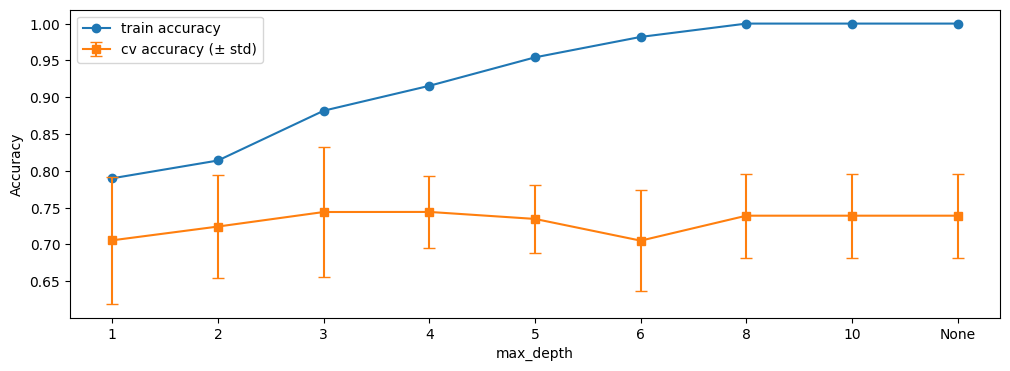

In [82]:
x = range(len(depths))
labels = [str(d) for d in depths]

plt.figure(figsize=( 12, 4))
plt.plot(x, depth_df["train_acc"], "o-", label="train accuracy")
plt.errorbar(x, depth_df["cv_acc"], yerr=depth_df["cv_std"], fmt="s-", capsize=4, label="cv accuracy (± std)")

plt.xticks(x, labels)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

c<br>
we must choose the depth where cv accuracy is best, relatively to train accuracy, so it's gonna be depth 2 (for very simple) or 3 (where balance between accuracy and cv accuracy is appropriate). <br>
the difference between 2, 3 and 4 is aproximately the same(1 std).


d

In [83]:
leaf_sizes = [1, 2, 5, 10, 20, 40]
leaf_results = []

for m in leaf_sizes:
    model = DecisionTreeClassifier(criterion="entropy", min_samples_leaf=m, random_state=SEED)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
    leaf_results.append({
        "min_samples_leaf": m,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std()
    })

print(pd.DataFrame(leaf_results).round(4))

   min_samples_leaf  train_acc  cv_acc  cv_std
0                 1     1.0000  0.7390  0.0568
1                 2     0.9662  0.7488  0.0541
2                 5     0.9106  0.7490  0.0802
3                10     0.8647  0.7782  0.0736
4                20     0.8068  0.7633  0.0090
5                40     0.7935  0.7341  0.0659


max_depth limits the depth of the whole tree samely on all the branches <br>
min_samples_leaf works more stretchy and allows to grow deeper

e

In [84]:
BEST_DEPTH = 3

best_model = DecisionTreeClassifier(criterion="entropy", max_depth=BEST_DEPTH, random_state=SEED)
best_model.fit(X_train, y_train)

test_acc = best_model.score(X_test, y_test)
n = len(y_test)
se = np.sqrt(test_acc * (1 - test_acc) / n)

print(f"test accuracy: {test_acc:.4f} ± {se:.4f}")

test accuracy: 0.7222 ± 0.0472


the huge gap between 100% train accuracy and much lower cv accuracy at unlimited depth shows clear overfitting, where the tree memorized training noise.

Task 4 <br>
4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4-4

In [85]:
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options: iprint")

a

In [86]:
models = [
    ("Tree (depth=3)", DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)),
    ("Unlimited Tree", DecisionTreeClassifier(criterion="entropy", random_state=SEED)),
    ("LogReg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)))
]
for name, m in models:
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=("accuracy", "f1"))
    print(f"{name} -> CV Acc: {s['test_accuracy'].mean():.3f} +- {s['test_accuracy'].std():.3f}, F1: {s['test_f1'].mean():.3f}")

Tree (depth=3) -> CV Acc: 0.744 +- 0.088, F1: 0.692
Unlimited Tree -> CV Acc: 0.739 +- 0.057, F1: 0.708
LogReg -> CV Acc: 0.845 +- 0.053, F1: 0.826


b

In [87]:
scaler = StandardScaler()
t1 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
t2 = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(scaler.fit_transform(X_train), y_train)

print("Agreement:", np.mean(t1.predict(X_test) == t2.predict(scaler.transform(X_test))))

Agreement: 1.0


agreement is 100% between trees <br>
decision trees only care about the relative order of values, and standard scaling saves this exact order

c

In [88]:
m_tree = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
m_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)

for name, m in [("Tree", m_tree), ("LogReg", m_lr)]:
    p = m.predict(X_test)
    print(f"{name} | Acuracy: {accuracy_score(y_test, p):.3f}, F1: {f1_score(y_test, p):.3f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, p))

Tree | Acuracy: 0.722, F1: 0.706
Confusion Matrix:
 [[35 13]
 [12 30]]
LogReg | Acuracy: 0.778, F1: 0.750
Confusion Matrix:
 [[40  8]
 [12 30]]


d<br>
i'd use logistic regression, because the difference between tree and logreg are approximately the same. the only reason to choose tree is that it has less std than logreg


Task 5 <br>
5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5-5

In [89]:
from sklearn.tree import export_text

shallow = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
print(export_text(shallow, feature_names=feature_names, show_weights=True))
ranked = sorted(zip(shallow.feature_importances_, feature_names), reverse=True)
print([(name, round(float(imp), 3)) for imp, name in ranked[:5]])

|--- thal <= 4.50
|   |--- ca <= 0.50
|   |   |--- age <= 58.50
|   |   |   |--- weights: [62.00, 1.00] class: 0
|   |   |--- age >  58.50
|   |   |   |--- weights: [16.00, 7.00] class: 0
|   |--- ca >  0.50
|   |   |--- sex <= 0.50
|   |   |   |--- weights: [11.00, 2.00] class: 0
|   |   |--- sex >  0.50
|   |   |   |--- weights: [2.00, 13.00] class: 1
|--- thal >  4.50
|   |--- oldpeak <= 0.85
|   |   |--- chol <= 240.50
|   |   |   |--- weights: [12.00, 4.00] class: 0
|   |   |--- chol >  240.50
|   |   |   |--- weights: [3.00, 11.00] class: 1
|   |--- oldpeak >  0.85
|   |   |--- cp <= 3.50
|   |   |   |--- weights: [5.00, 10.00] class: 1
|   |   |--- cp >  3.50
|   |   |   |--- weights: [1.00, 47.00] class: 1

[('thal', 0.44), ('ca', 0.14), ('oldpeak', 0.111), ('sex', 0.097), ('age', 0.09)]


1<br>
two rules: <BR>
1. it thal >4.50 and oldpeak > 0.85 and cp > 3.50 then DISEASE (48 patients)
2. if thal <=4.50 and ca <= 0.50 and age <= 58.50 then not Disease (23 patients)


2<br>
top 5 features is thal, ca, oldpeak, sex, age<br>
mean decrease in impurity is biased towards continuous features, it doesnt always represent matter of correlated features

3
tree at this case is responsible for optimising entropy, and not accuracy of classes. even if they have the same class, it may clean one node 